# 06 — Benchmark DSP: Hybrid / Square-Law / FFT Hilbert

## Mục tiêu

Với cùng tín hiệu đầu vào và cùng cấu hình lọc đã khóa trong `bandpass_config.json`, notebook đánh giá độ trung thực của Hybrid và khảo sát Square-Law so với FFT Hilbert (tham chiếu offline).

Notebook thực hiện:
1. Đọc `manifest_clean.csv`, resample tín hiệu về `fs_hz` theo metadata khi cần.
2. Truyền tường minh bậc BPF/LPF từ cấu hình vào cả ba thuật toán envelope.
3. Đánh giá dạng sóng sau warm-up và cắt biên cuối để giảm ảnh hưởng biên của tham chiếu Hilbert theo khối.
4. Báo Pearson/lag cho cả ba phương pháp; chỉ báo MAE/RMSE/NRMSE biên độ thô khi hai tín hiệu cùng đơn vị (Hybrid và Hilbert).
5. Báo thêm NRMSE dạng hình dạng sau căn chỉnh gain để khảo sát tương quan hình dạng, không dùng chỉ số này để kết luận độ trung thực biên độ tuyệt đối.
6. So phổ envelope ở các tần số lỗi lý thuyết và hài. Phổ được chuẩn hóa theo đỉnh riêng của từng phương pháp, nên các chỉ số phổ là so sánh **hình dạng phổ tương đối**, không phải so sánh biên độ tuyệt đối giữa Square-Law và Hilbert.
7. Xuất kết quả theo từng file, theo nhãn, và danh sách lỗi.

**Giới hạn:** Hilbert là tham chiếu offline, không phải ứng viên triển khai MCU. Notebook này không đánh giá MLP hay tài nguyên trên STM32F4. Không kết luận rằng các tần số lỗi lý thuyết phải xuất hiện trên mọi file, đặc biệt là Normal.

> Sau khi sửa, output cũ đã được xóa để tránh dùng nhầm kết quả tạo từ mã phiên bản trước. Hãy chạy **Restart Kernel and Run All** trong môi trường có dữ liệu dự án rồi kiểm tra CSV lỗi trước khi sử dụng kết quả.


In [21]:
from pathlib import Path
import json
import re

import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from scipy.signal import butter, sosfilt

from common import io_utils, dsp, config as cfg

# 1. Nạp manifest và cấu hình đã khóa
Đường dẫn được giữ theo cấu trúc notebook giai đoạn 1: `./outputs/tables/manifest_clean.csv` và `bandpass_config.json`. Nếu notebook được chạy từ thư mục khác, sửa `PROJECT_OUTPUT_DIR` bên dưới.

In [22]:
PROJECT_OUTPUT_DIR = Path('./outputs')
TABLES_DIR = PROJECT_OUTPUT_DIR / 'tables'
FIGURES_DIR = PROJECT_OUTPUT_DIR / 'figures'
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

manifest_path = TABLES_DIR / 'manifest_clean.csv'
config_path = TABLES_DIR / 'bandpass_config.json'
if not manifest_path.exists():
    raise FileNotFoundError(f'Không tìm thấy {manifest_path}; hãy kiểm tra thư mục làm việc.')
if not config_path.exists():
    raise FileNotFoundError(f'Không tìm thấy {config_path}; hãy chạy notebook tạo cấu hình DSP trước.')

manifest = pd.read_csv(manifest_path)
required_cols = ['file_path', 'label', 'load_hp', 'resolved_sample_rate_hz']
missing_cols = [c for c in required_cols if c not in manifest.columns]
if missing_cols:
    raise ValueError(f'Manifest thiếu cột bắt buộc: {missing_cols}')
if manifest.empty:
    raise ValueError('Manifest không có file để vẽ.')
if manifest['file_path'].isna().any():
    raise ValueError('Manifest có file_path rỗng.')

with open(config_path, encoding='utf-8') as f:
    CONF = json.load(f)

BAND_HZ = tuple(float(v) for v in CONF['band_hz'])
LP_CUTOFF_HZ = float(CONF['lp_cutoff_hz'])
FS = float(CONF['fs_hz'])
WARMUP = int(CONF.get('warmup_samples', 0))
BPF_ORDER = int(CONF.get('bandpass_order', dsp.BENCHMARK_BANDPASS_ORDER))
LOWPASS_ORDER = int(CONF.get('lowpass_order', dsp.BENCHMARK_LOWPASS_ORDER))
# Hilbert là phép biến đổi theo khối; bỏ thêm đoạn cuối để giảm ảnh hưởng biên.
# Mặc định dùng cùng số mẫu như warm-up đầu file, có thể ghi đè bằng config.
EDGE_TRIM_SAMPLES = int(CONF.get('hilbert_edge_trim_samples', WARMUP))
if EDGE_TRIM_SAMPLES < 0:
    raise ValueError('hilbert_edge_trim_samples phải >= 0.')

# Chỉ thay FILE_INDEX để chọn file khác trong manifest.
FILE_INDEX = 14
SEGMENT_SECONDS = 0.05  # thời lượng hiển thị sau warm-up; không ảnh hưởng dữ liệu DSP

manifest = manifest.sort_values(['label', 'file_path']).reset_index(drop=True)
if not 0 <= FILE_INDEX < len(manifest):
    raise IndexError(f'FILE_INDEX phải nằm trong [0, {len(manifest)-1}].')
row = manifest.iloc[FILE_INDEX]

print(f'File {FILE_INDEX + 1}/{len(manifest)}: {row["file_path"]}')
print(f'Nhãn={row["label"]}; tải={row["load_hp"]} HP; nguồn fs={row["resolved_sample_rate_hz"]} Hz')
print(f'BPF={BAND_HZ[0]:g}–{BAND_HZ[1]:g} Hz, bậc={BPF_ORDER}; LPF={LP_CUTOFF_HZ:g} Hz, bậc={LOWPASS_ORDER}')
print(f'fs={FS:g} Hz; warm-up đầu={WARMUP} mẫu ({1000 * WARMUP / FS:.2f} ms); trim cuối={EDGE_TRIM_SAMPLES} mẫu ({1000 * EDGE_TRIM_SAMPLES / FS:.2f} ms)')


File 15/40: F:\CODE\NCKH_TinyML\TinyML_CWRU\data\raw\12k_Drive_End_Bearing_Fault_Data\IR\007\107_2.mat
Nhãn=IR; tải=2 HP; nguồn fs=12000.0 Hz
BPF=2300–3800 Hz, bậc=4; LPF=750 Hz, bậc=2
fs=12000 Hz; warm-up đầu=2048 mẫu (170.67 ms); trim cuối=2048 mẫu (170.67 ms)


# 3. Tạo ba envelope trên cùng tín hiệu

Các thuật toán nhận cùng tín hiệu và truyền tường minh cùng bậc lọc. **Không vẽ đầu ra Square-Law như thể nó có cùng đơn vị biên độ với Hybrid/Hilbert**: Square-Law là tín hiệu miền công suất (bình phương). Vì vậy hình bên dưới có hai panel:

- Panel trên: tín hiệu sau BPF cùng envelope Hybrid và Hilbert, có thể so sánh biên độ trực tiếp.
- Panel dưới: các envelope sau khi trừ DC và chuẩn hóa RMS AC, chỉ dùng để so sánh hình dạng biến thiên; không thể hiện độ trung thực biên độ tuyệt đối.

Đồ thị dùng trục thời gian gốc, chưa căn chỉnh lag.


In [23]:
METHODS = [
    ('Square-Law', 'square_law', 'tab:blue'),
    ('Hybrid', 'hybrid', 'tab:green'),
    ('FFT Hilbert', 'hilbert_offline', 'tab:orange'),
]


def make_envelope(x, method_key):
    common_kwargs = {
        'band': BAND_HZ,
        'bandpass_order': BPF_ORDER,
        'lp_cutoff': LP_CUTOFF_HZ,
        'lowpass_order': LOWPASS_ORDER,
        'remove_dc': False,
    }
    if method_key == 'square_law':
        env = dsp.square_law_envelope(x, FS, **common_kwargs)
    elif method_key == 'hybrid':
        env = dsp.hybrid_envelope(x, FS, **common_kwargs)
    elif method_key == 'hilbert_offline':
        env = dsp.hilbert_envelope(x, FS, **common_kwargs)
    else:
        raise ValueError(f'Phương pháp không hợp lệ: {method_key}')

    env = np.asarray(env, dtype=np.float64).reshape(-1)
    if len(env) != len(x):
        raise ValueError(f'{method_key}: độ dài envelope={len(env)}, tín hiệu={len(x)}.')
    if not np.isfinite(env).all():
        raise ValueError(f'{method_key}: envelope có NaN/Inf.')
    return env

source_fs = float(row['resolved_sample_rate_hz'])
x = np.asarray(
    io_utils.load_de_signal_resampled(Path(str(row['file_path'])), source_fs, FS),
    dtype=np.float64,
).reshape(-1)
if not np.isfinite(x).all():
    raise ValueError('Tín hiệu đầu vào có NaN/Inf.')
if len(x) <= WARMUP + 10:
    raise ValueError('Tín hiệu quá ngắn sau warm-up.')

# Tín hiệu miền thời gian cần phủ envelope: BPF Butterworth causal SOS.
bpf_sos = butter(BPF_ORDER, BAND_HZ, btype='bandpass', fs=FS, output='sos')
x_bp = sosfilt(bpf_sos, x)

envelopes = {
    key: make_envelope(x, key)
    for _, key, _ in METHODS
}

for _, key, _ in METHODS:
    if len(envelopes[key]) != len(x_bp):
        raise ValueError(f'{key}: độ dài không khớp với tín hiệu BPF.')

print(f'Đã tính {len(METHODS)} envelope trên cùng {len(x):,} mẫu.')


Đã tính 3 envelope trên cùng 122,136 mẫu.


# 4. Phổ envelope

Envelope được giảm mẫu trên toàn file trước khi bỏ vùng phân tích, tránh khởi tạo lại xử lý tại đầu đoạn phân tích. Trước khi tính FFT, notebook căn chỉnh lag, bỏ DC và tính phổ bằng cùng hàm/cửa sổ.

Để không so sánh trực tiếp đại lượng có đơn vị khác nhau, mỗi phương pháp được chuẩn hóa theo **đỉnh phổ riêng** trong dải `0–FMAX_HZ`. Sai số trong bảng phổ vì vậy phản ánh mức giống nhau của **phân bố phổ tương đối** tại các tần số lỗi lý thuyết và hài, không phản ánh sai số biên độ tuyệt đối. Độ trung thực biên độ tuyệt đối giữa Hybrid và Hilbert được đánh giá riêng ở benchmark dạng sóng.

Kết quả được tách theo nhãn. Với Normal, BPFO/BPFI/BSF/FTF chỉ là tần số lý thuyết tham chiếu, không được diễn giải mặc định là thành phần lỗi thực sự xuất hiện.


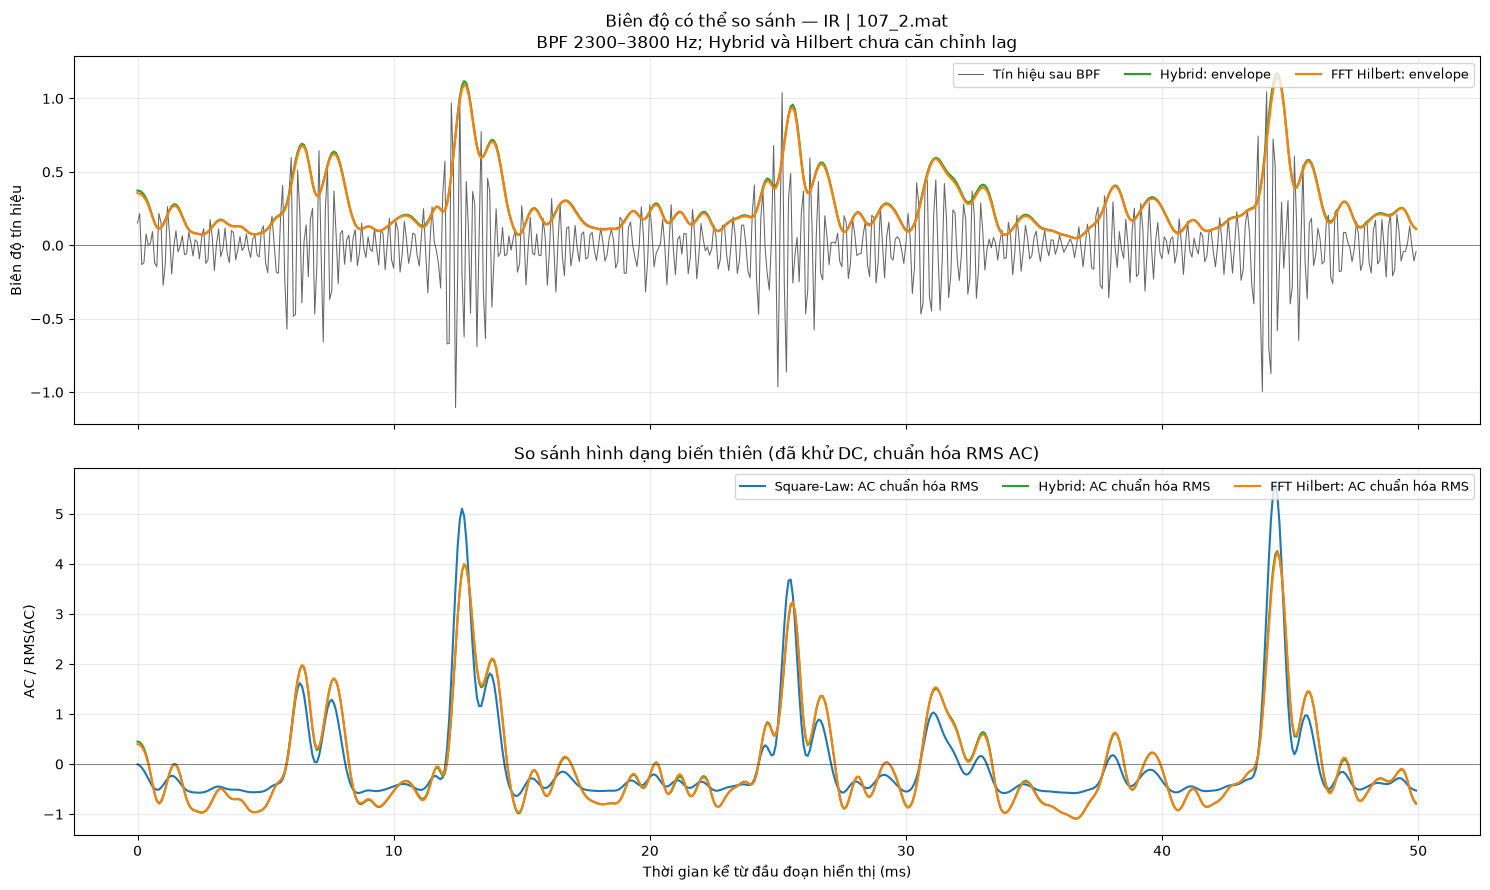

Đã lưu hình: outputs\figures\06_envelope_overlay_107_2.png


In [24]:
start = WARMUP
n_plot = min(int(round(SEGMENT_SECONDS * FS)), len(x) - start)
if n_plot <= 10:
    raise ValueError('Đoạn tín hiệu sau warm-up quá ngắn để vẽ.')
stop = start + n_plot

time_ms = np.arange(n_plot, dtype=np.float64) * 1000.0 / FS
x_seg = x_bp[start:stop]
fig, (ax_amp, ax_shape) = plt.subplots(2, 1, figsize=(15, 9), sharex=True)

# Top panel: amplitude-compatible overlays only.
ax_amp.plot(time_ms, x_seg, color='0.25', linewidth=0.75, alpha=0.8,
            label='Tín hiệu sau BPF', zorder=1)
for name, key, color in METHODS:
    if key not in ('hybrid', 'hilbert_offline'):
        continue
    env_seg = envelopes[key][start:stop]
    ax_amp.plot(time_ms, env_seg, color=color, linewidth=1.6,
                label=f'{name}: envelope', zorder=3)
ax_amp.axhline(0.0, color='black', linewidth=0.6, alpha=0.5)
ax_amp.set_title(
    f'Biên độ có thể so sánh — {row["label"]} | {Path(str(row["file_path"])).name}\n'
    f'BPF {BAND_HZ[0]:g}–{BAND_HZ[1]:g} Hz; Hybrid và Hilbert chưa căn chỉnh lag'
)
ax_amp.set_ylabel('Biên độ tín hiệu')
ax_amp.grid(True, alpha=0.25)
ax_amp.legend(ncol=3, fontsize=9, loc='upper right')

# Bottom panel: normalize AC-RMS for shape inspection; Square-Law remains power-domain.
for name, key, color in METHODS:
    env_seg = np.asarray(envelopes[key][start:stop], dtype=np.float64)
    env_ac = env_seg - np.mean(env_seg)
    scale = float(np.sqrt(np.mean(env_ac ** 2)))
    if scale > 1e-20:
        env_shape = env_ac / scale
    else:
        env_shape = np.zeros_like(env_ac)
    ax_shape.plot(time_ms, env_shape, color=color, linewidth=1.5,
                  label=f'{name}: AC chuẩn hóa RMS')
ax_shape.axhline(0.0, color='black', linewidth=0.6, alpha=0.5)
ax_shape.set_title('So sánh hình dạng biến thiên (đã khử DC, chuẩn hóa RMS AC)')
ax_shape.set_xlabel('Thời gian kể từ đầu đoạn hiển thị (ms)')
ax_shape.set_ylabel('AC / RMS(AC)')
ax_shape.grid(True, alpha=0.25)
ax_shape.legend(ncol=3, fontsize=9, loc='upper right')
fig.tight_layout()

safe_stem = re.sub(r'[^A-Za-z0-9._-]+', '_', Path(str(row['file_path'])).stem)
figure_path = FIGURES_DIR / f'06_envelope_overlay_{safe_stem}.png'
fig.savefig(figure_path, dpi=180, bbox_inches='tight')
plt.show()
print(f'Đã lưu hình: {figure_path}')


# 4. Benchmark dạng sóng trên toàn bộ manifest

Với từng file, dùng FFT Hilbert làm tham chiếu offline. Lag được ước lượng sau warm-up và trước khi cắt biên cuối. `EDGE_TRIM_SAMPLES` được loại khỏi cuối file để giảm ảnh hưởng biên của phép Hilbert theo khối; cùng một vùng thời gian hợp lệ được dùng cho mọi phương pháp.

Pearson và lag được báo cho cả ba phương pháp. Do Square-Law tạo tín hiệu miền công suất (đơn vị bình phương), MAE/RMSE/NRMSE biên độ thô của Square-Law **không được xem là so sánh biên độ vật lý tương đương** và sẽ để NaN. Với cả ba phương pháp, notebook bổ sung `nrmse_ac_shape_only`, sau khi fit gain trên thành phần AC, để so sánh hình dạng bỏ qua khác biệt scale. Chỉ số shape-fit không thay thế chỉ số biên độ tuyệt đối.


In [25]:
# Tham số benchmark. Không thay đổi cấu hình DSP đã khóa.
MAX_LAG_SAMPLES = 100       # giới hạn tìm lag ở fs đầu vào
FMAX_HZ = 500.0             # dải envelope dùng để tìm/so đỉnh phổ
SEARCH_WIDTH_HZ = 3.0       # tìm đỉnh cục bộ trong ±3 Hz quanh tần số lý thuyết
HARMONICS = (1, 2, 3)
REL_ERROR_FLOOR = 1e-3      # tránh %/dB khi đỉnh Hilbert gần 0 sau chuẩn hóa
REFERENCE_KEY = 'hilbert_offline'
FAULT_NAMES = ('BPFO', 'BPFI', 'BSF', 'FTF')


def estimate_lag(candidate, reference, warmup_samples, max_lag_samples, end_trim_samples=0):
    """Ước lượng lag; lag > 0 nghĩa candidate trễ hơn reference. Bỏ cả biên đầu/cuối."""
    candidate = np.asarray(candidate, dtype=np.float64).reshape(-1)
    reference = np.asarray(reference, dtype=np.float64).reshape(-1)
    if len(candidate) != len(reference):
        raise ValueError('Candidate và reference phải có cùng độ dài trước khi tìm lag.')
    if end_trim_samples < 0:
        raise ValueError('end_trim_samples phải >= 0.')
    valid_end = min(len(candidate), len(reference)) - int(end_trim_samples)
    if valid_end <= warmup_samples + max_lag_samples + 10:
        raise ValueError('Tín hiệu quá ngắn sau khi bỏ warm-up/biên cuối để tìm lag.')

    a = candidate[warmup_samples:valid_end]
    b = reference[warmup_samples:valid_end]
    best_lag, best_corr = 0, -np.inf
    for lag in range(-int(max_lag_samples), int(max_lag_samples) + 1):
        # So sánh candidate[i + lag] với reference[i].
        if lag >= 0:
            aa = a[lag:]
            bb = b[:len(b) - lag] if lag else b
        else:
            aa = a[:len(a) + lag]
            bb = b[-lag:]
        n = min(len(aa), len(bb))
        if n <= 10:
            continue
        aa = aa[:n] - np.mean(aa[:n])
        bb = bb[:n] - np.mean(bb[:n])
        denom = float(np.linalg.norm(aa) * np.linalg.norm(bb))
        corr = float(np.dot(aa, bb) / denom) if denom > 1e-20 else -np.inf
        if corr > best_corr:
            best_lag, best_corr = lag, corr
    if not np.isfinite(best_corr):
        raise ValueError('Không ước lượng được lag; tín hiệu có thể gần hằng số.')
    return int(best_lag), float(best_corr)


def align_to_reference(series_by_key, reference_key, warmup_samples, max_lag_samples, end_trim_samples=0):
    """Căn chỉnh về Hilbert, chỉ giữ vùng hợp lệ sau warm-up và trước biên cuối."""
    ref = np.asarray(series_by_key[reference_key], dtype=np.float64).reshape(-1)
    lags = {reference_key: 0}
    lag_corrs = {reference_key: 1.0}
    for _, key, _ in METHODS:
        if key == reference_key:
            continue
        lag, corr = estimate_lag(
            series_by_key[key], ref, warmup_samples, max_lag_samples, end_trim_samples
        )
        lags[key], lag_corrs[key] = lag, corr

    arrays = {k: np.asarray(series_by_key[k], dtype=np.float64).reshape(-1)
              for _, k, _ in METHODS}
    # ref-index i must satisfy warmup <= i + lag[k] < len[k] - end_trim for every method.
    ref_start = max(int(warmup_samples - lags[k]) for k in arrays)
    ref_end = min(int(len(arrays[k]) - end_trim_samples - lags[k]) for k in arrays)
    if ref_end <= ref_start:
        raise ValueError('Không còn vùng chồng lấp sau warm-up, trim cuối và căn chỉnh lag.')

    aligned = {
        key: arrays[key][ref_start + lags[key]:ref_end + lags[key]]
        for key in arrays
    }
    if len({len(v) for v in aligned.values()}) != 1:
        raise RuntimeError('Lỗi căn chỉnh: độ dài các envelope không bằng nhau.')
    return aligned, lags, lag_corrs


def rms(values):
    values = np.asarray(values, dtype=np.float64)
    return float(np.sqrt(np.mean(values ** 2))) if len(values) else np.nan


def safe_pearson(a, b):
    a = np.asarray(a, dtype=np.float64)
    b = np.asarray(b, dtype=np.float64)
    if len(a) < 2 or np.std(a) <= 1e-20 or np.std(b) <= 1e-20:
        return np.nan
    return float(np.corrcoef(a, b)[0, 1])


def safe_int(value):
    return None if value is None or pd.isna(value) else int(value)


def get_rpm(row):
    """Ưu tiên RPM đã khóa trong manifest; fallback theo tải danh định khi cần."""
    for col in ('rpm', 'rpm_from_file'):
        value = row.get(col)
        if value is not None and not pd.isna(value):
            value = float(value)
            if np.isfinite(value) and value > 0:
                return value
    load_value = row.get('load_hp')
    if load_value is None or pd.isna(load_value):
        raise ValueError('Không có RPM hợp lệ và manifest thiếu load_hp để fallback.')
    load = int(load_value)
    if load not in cfg.NOMINAL_RPM_BY_LOAD:
        raise ValueError(f'Không có RPM hợp lệ trong manifest và không có RPM danh định cho tải {load} HP.')
    return float(cfg.NOMINAL_RPM_BY_LOAD[load])


def slug(value):
    value = re.sub(r'[^A-Za-z0-9._-]+', '_', str(value).strip())
    return value.strip('._-') or 'unknown'


def metrics_for_waveforms(case, aligned, lags, lag_corrs):
    """Metrics waveform; biên độ thô chỉ hợp lệ khi đơn vị cùng loại."""
    ref = np.asarray(aligned[REFERENCE_KEY], dtype=np.float64)
    ref_ac = ref - np.mean(ref)
    ref_rms = rms(ref)
    ref_ac_rms = rms(ref_ac)
    rows = []
    eps = 1e-12

    for method_name, key, _ in METHODS:
        env = np.asarray(aligned[key], dtype=np.float64)
        env_ac = env - np.mean(env)
        lag = int(lags[key])
        # Gain LS trên thành phần AC: chỉ dùng đo độ giống nhau hình dạng, không phải fidelity biên độ.
        denom = float(np.dot(env_ac, env_ac))
        gain_ac = float(np.dot(env_ac, ref_ac) / denom) if denom > eps else np.nan
        if np.isfinite(gain_ac):
            fitted_ac = gain_ac * env_ac
            nrmse_shape = rms(fitted_ac - ref_ac) / max(ref_ac_rms, eps)
        else:
            nrmse_shape = np.nan

        # Square-Law trả tín hiệu miền công suất (x^2), không cùng đơn vị với |analytic signal|.
        amplitude_comparable = key in ('hybrid', REFERENCE_KEY)
        if amplitude_comparable:
            err = env - ref
            err_ac = env_ac - ref_ac
            mae = float(np.mean(np.abs(err)))
            rmse_env = rms(err)
            nrmse_dc = rmse_env / max(ref_rms, eps)
            nrmse_ac_raw = rms(err_ac) / max(ref_ac_rms, eps)
        else:
            mae = rmse_env = nrmse_dc = nrmse_ac_raw = np.nan

        rows.append({
            'case_id': case['case_id'],
            'file_path': case['file_path'],
            'filename': case['filename'],
            'label': case['label'],
            'record_group': case['record_group'],
            'load_hp': case['load_hp'],
            'fault_diameter_mils': case['fault_diameter_mils'],
            'source_fs_hz': case['source_fs_hz'],
            'fs_hz': FS,
            'method': method_name,
            'method_key': key,
            'reference_method': METHODS[2][0],
            'n_samples_compared_after_trim': len(env),
            'edge_trim_start_samples': WARMUP,
            'edge_trim_end_samples': EDGE_TRIM_SAMPLES,
            'lag_samples_vs_hilbert': lag,
            'lag_ms_vs_hilbert': 1000.0 * lag / FS,
            'alignment_correlation_at_lag': float(lag_corrs[key]),
            'pearson_vs_hilbert': safe_pearson(env, ref),
            'amplitude_metric_comparable_to_hilbert': amplitude_comparable,
            'mae_envelope': mae,
            'rmse_envelope': rmse_env,
            'nrmse_envelope_preserve_dc': nrmse_dc,
            'nrmse_ac_raw_scale': nrmse_ac_raw,
            'gain_fit_ac_to_hilbert_for_shape_only': gain_ac,
            'nrmse_ac_shape_only': nrmse_shape,
            'envelope_mean': float(np.mean(env)),
            'envelope_rms': rms(env),
            'envelope_ac_rms': rms(env_ac),
        })
    return pd.DataFrame(rows)


# 5. Benchmark phổ envelope tại tần số lỗi

Các envelope được giảm mẫu trên toàn file trước khi trích vùng hợp lệ. Sau đó căn chỉnh lag, bỏ DC và tính FFT bằng cùng cửa sổ. Mỗi phương pháp được chuẩn hóa bằng đỉnh phổ riêng trong dải `0–FMAX_HZ`, do vậy so sánh phổ ở đây là so sánh phân bố phổ tương đối, không phải biên độ tuyệt đối.

Bảng theo file lưu nhãn riêng; phần tổng hợp được nhóm theo `label`, để không gộp Normal vào bản ghi lỗi. Với Normal, BPFO/BPFI/BSF/FTF chỉ là các tần số lý thuyết kiểm tra, không đồng nghĩa đã có khuyết tật.


In [26]:
def peak_near_frequency(freqs, magnitude, target_hz, search_width_hz, fmax_hz):
    """Trả về tần số đỉnh cục bộ và biên độ; NaN nếu tần số ngoài dải."""
    freqs = np.asarray(freqs, dtype=np.float64)
    magnitude = np.asarray(magnitude, dtype=np.float64)
    if len(freqs) == 0 or not np.isfinite(target_hz) or target_hz <= 0:
        return np.nan, np.nan
    if target_hz > min(fmax_hz, float(freqs[-1])):
        return np.nan, np.nan
    mask = (
        (freqs >= max(0.0, target_hz - search_width_hz))
        & (freqs <= min(fmax_hz, target_hz + search_width_hz))
    )
    idxs = np.flatnonzero(mask)
    if len(idxs) == 0:
        return np.nan, np.nan
    idx = idxs[int(np.nanargmax(magnitude[idxs]))]
    return float(freqs[idx]), float(magnitude[idx])


def spectrum_metrics(case, envelopes):
    """So sánh hình dạng phổ envelope sau decimate, chuẩn hóa theo đỉnh riêng từng phương pháp."""
    decimated = {}
    fs_env = None
    for _, key, _ in METHODS:
        env_d, fs_current = dsp.decimate_envelope(envelopes[key], FS)
        env_d = np.asarray(env_d, dtype=np.float64).reshape(-1)
        if not np.isfinite(env_d).all():
            raise ValueError(f'{key}: envelope sau decimate có NaN/Inf.')
        if fs_env is None:
            fs_env = float(fs_current)
        elif not np.isclose(fs_env, float(fs_current)):
            raise ValueError('Tần số lấy mẫu envelope không đồng nhất giữa các phương pháp.')
        decimated[key] = env_d

    if len({len(v) for v in decimated.values()}) != 1:
        raise ValueError('Độ dài envelope sau decimate không đồng nhất.')
    warmup_env = int(math.ceil(WARMUP * fs_env / FS))
    end_trim_env = int(math.ceil(EDGE_TRIM_SAMPLES * fs_env / FS))
    max_lag_env = max(1, int(math.ceil(MAX_LAG_SAMPLES * fs_env / FS)))
    aligned, lags, lag_corrs = align_to_reference(
        decimated, REFERENCE_KEY, warmup_env, max_lag_env, end_trim_env
    )

    fmax_hz = min(float(FMAX_HZ), fs_env / 2.0)
    spectra = {}
    for method_name, key, _ in METHODS:
        env = np.asarray(aligned[key], dtype=np.float64)
        env_ac = env - np.mean(env)
        freqs, mag = dsp.compute_fft(env_ac, fs_env, apply_window=True)
        freqs = np.asarray(freqs, dtype=np.float64)
        mag = np.asarray(mag, dtype=np.float64)
        if len(freqs) != len(mag) or len(freqs) < 2:
            raise ValueError(f'FFT không hợp lệ cho {key}.')
        band_mask = (freqs >= 0.0) & (freqs <= fmax_hz)
        if not np.any(band_mask):
            raise ValueError(f'Không có bin FFT trong dải 0–{fmax_hz:g} Hz.')
        method_peak = float(np.max(mag[band_mask]))
        if not np.isfinite(method_peak) or method_peak <= 1e-20:
            raise ValueError(f'Không có đỉnh phổ hợp lệ cho {key}.')
        spectra[key] = {
            'method': method_name,
            'env_ac': env_ac,
            'freqs': freqs,
            'mag': mag,
            'band_mask': band_mask,
            'method_peak': method_peak,
            'mag_self_norm': mag / method_peak,
            'lag_env_samples': int(lags[key]),
            'lag_env_ms': 1000.0 * int(lags[key]) / fs_env,
            'lag_corr': float(lag_corrs[key]),
            'fs_env_hz': fs_env,
        }

    fault_rows = []
    faults = case['faults']
    ref_spec = spectra[REFERENCE_KEY]
    eps = 1e-12
    for fault_name in FAULT_NAMES:
        if fault_name not in faults:
            continue
        base_hz = float(faults[fault_name])
        for harmonic in HARMONICS:
            target_hz = base_hz * harmonic
            ref_peak_hz, ref_amp = peak_near_frequency(
                ref_spec['freqs'], ref_spec['mag_self_norm'],
                target_hz, SEARCH_WIDTH_HZ, fmax_hz,
            )
            for method_name, key, _ in METHODS:
                spec = spectra[key]
                peak_hz, amp = peak_near_frequency(
                    spec['freqs'], spec['mag_self_norm'],
                    target_hz, SEARCH_WIDTH_HZ, fmax_hz,
                )
                valid = np.isfinite(amp) and np.isfinite(ref_amp)
                signed_err = float(amp - ref_amp) if valid else np.nan
                abs_err = float(abs(signed_err)) if valid else np.nan
                if valid and ref_amp >= REL_ERROR_FLOOR:
                    rel_err_pct = 100.0 * signed_err / ref_amp
                    error_db = 20.0 * np.log10(max(float(amp), eps) / max(float(ref_amp), eps))
                else:
                    rel_err_pct, error_db = np.nan, np.nan
                fault_rows.append({
                    'case_id': case['case_id'],
                    'file_path': case['file_path'],
                    'filename': case['filename'],
                    'label': case['label'],
                    'record_group': case['record_group'],
                    'load_hp': case['load_hp'],
                    'fault_diameter_mils': case['fault_diameter_mils'],
                    'rpm': case['rpm'],
                    'method': method_name,
                    'method_key': key,
                    'reference_method': METHODS[2][0],
                    'fault_component': fault_name,
                    'harmonic': harmonic,
                    'target_frequency_hz': target_hz,
                    'search_width_hz': SEARCH_WIDTH_HZ,
                    'observed_peak_frequency_hz': peak_hz,
                    'reference_peak_frequency_hz': ref_peak_hz,
                    'peak_frequency_error_hz': peak_hz - target_hz if np.isfinite(peak_hz) else np.nan,
                    'method_own_peak_magnitude': spec['method_peak'],
                    'amplitude_self_norm': amp,
                    'reference_amplitude_self_norm': ref_amp,
                    'signed_shape_error_self_norm': signed_err,
                    'absolute_shape_error_self_norm': abs_err,
                    'relative_shape_error_pct': rel_err_pct,
                    'shape_error_db_vs_hilbert': error_db,
                    'reference_floor_used_for_relative_error': REL_ERROR_FLOOR,
                    'fs_envelope_hz': fs_env,
                    'fft_bin_hz': float(spec['freqs'][1] - spec['freqs'][0]),
                    'alignment_lag_env_samples_vs_hilbert': spec['lag_env_samples'],
                    'alignment_lag_env_ms_vs_hilbert': spec['lag_env_ms'],
                    'alignment_correlation_at_lag': spec['lag_corr'],
                })
    return pd.DataFrame(fault_rows)


# 6. Chạy benchmark trên toàn bộ manifest và lưu CSV

Nếu một file lỗi đọc/xử lý, notebook ghi lỗi vào CSV và tiếp tục để hoàn thành báo cáo chẩn đoán. Không được coi benchmark hoàn tất nếu `06_dsp_benchmark_errors.csv` có dòng lỗi hoặc số file thành công nhỏ hơn số dòng trong manifest.

Các metrics biên độ tuyệt đối của Square-Law được đặt NaN vì đầu ra có đơn vị bình phương tín hiệu. Bảng vẫn báo Pearson, lag và NRMSE hình dạng sau gain-fit. Bảng phổ chuẩn hóa theo đỉnh riêng từng phương pháp và tổng hợp theo nhãn để tách Normal khỏi các bản ghi lỗi.


In [27]:
# Chạy benchmark trên TOÀN BỘ manifest; FILE_INDEX chỉ tác động đến hình minh họa phía trên.
waveform_tables = []
spectrum_tables = []
error_rows = []
processed_cases = 0

for manifest_idx, row_bench in manifest.iterrows():
    file_path = str(row_bench['file_path'])
    try:
        source_fs = float(row_bench['resolved_sample_rate_hz'])
        x_bench = np.asarray(
            io_utils.load_de_signal_resampled(Path(file_path), source_fs, FS),
            dtype=np.float64,
        ).reshape(-1)
        if not np.isfinite(x_bench).all():
            raise ValueError('Tín hiệu đầu vào có NaN/Inf.')
        if len(x_bench) <= WARMUP + EDGE_TRIM_SAMPLES + MAX_LAG_SAMPLES + 10:
            raise ValueError('File quá ngắn sau warm-up/trim cuối để đo lag/metrics.')

        env_bench = {key: make_envelope(x_bench, key) for _, key, _ in METHODS}
        aligned_bench, lags_bench, lag_corr_bench = align_to_reference(
            env_bench, REFERENCE_KEY, WARMUP, MAX_LAG_SAMPLES, EDGE_TRIM_SAMPLES
        )

        label = str(row_bench['label'])
        label_lower = label.strip().lower()
        record_group = 'Normal' if ('normal' in label_lower or label_lower in {'n', 'healthy'}) else 'Fault'
        load_value = row_bench.get('load_hp')
        load_hp = safe_int(load_value)
        diameter = safe_int(row_bench.get('fault_diameter_mils'))
        rpm = get_rpm(row_bench)
        fault_freqs = cfg.bearing_fault_frequencies(rpm)
        normalized_path = file_path.replace('\\', '/')
        filename = Path(normalized_path).name
        diameter_tag = 'na' if diameter is None else str(diameter)
        case_id = f'{int(manifest_idx):04d}_{slug(label)}_{slug(Path(filename).stem)}'
        case = {
            'case_id': case_id,
            'file_path': file_path,
            'filename': filename,
            'label': label,
            'record_group': record_group,
            'load_hp': load_hp,
            'fault_diameter_mils': diameter,
            'source_fs_hz': source_fs,
            'rpm': rpm,
            'faults': {str(k): float(v) for k, v in fault_freqs.items()
                       if np.isfinite(float(v))},
        }

        wave_df = metrics_for_waveforms(case, aligned_bench, lags_bench, lag_corr_bench)
        spec_df = spectrum_metrics(case, env_bench)
        waveform_tables.append(wave_df)
        spectrum_tables.append(spec_df)
        processed_cases += 1

        if processed_cases % 5 == 0 or processed_cases == len(manifest):
            print(f'Đã benchmark {processed_cases}/{len(manifest)} file...')

    except Exception as exc:
        error_rows.append({
            'manifest_row_index': int(manifest_idx),
            'file_path': file_path,
            'label': str(row_bench.get('label', '')),
            'error_type': type(exc).__name__,
            'error_message': str(exc),
        })
        print(f'[LỖI] {file_path}: {type(exc).__name__}: {exc}')

# Export waveform metrics and method-level summary.
if waveform_tables:
    waveform_by_file = pd.concat(waveform_tables, ignore_index=True)
    waveform_path = TABLES_DIR / '06_waveform_metrics_by_file.csv'
    waveform_by_file.to_csv(waveform_path, index=False, encoding='utf-8-sig')

    waveform_summary = (
        waveform_by_file.groupby(['method', 'method_key', 'amplitude_metric_comparable_to_hilbert'], as_index=False)
        .agg(
            n_files=('case_id', 'nunique'),
            pearson_mean=('pearson_vs_hilbert', 'mean'),
            pearson_std=('pearson_vs_hilbert', 'std'),
            # Raw-scale amplitude metrics are NaN for Square-Law by design.
            nrmse_envelope_mean=('nrmse_envelope_preserve_dc', 'mean'),
            nrmse_envelope_median=('nrmse_envelope_preserve_dc', 'median'),
            nrmse_ac_raw_scale_mean=('nrmse_ac_raw_scale', 'mean'),
            nrmse_ac_shape_only_mean=('nrmse_ac_shape_only', 'mean'),
            nrmse_ac_shape_only_median=('nrmse_ac_shape_only', 'median'),
            mae_mean=('mae_envelope', 'mean'),
            lag_samples_mean=('lag_samples_vs_hilbert', 'mean'),
            lag_samples_abs_median=('lag_samples_vs_hilbert', lambda s: float(np.median(np.abs(s)))),
        )
    )
    waveform_summary_path = TABLES_DIR / '06_waveform_metrics_summary_by_method.csv'
    waveform_summary.to_csv(waveform_summary_path, index=False, encoding='utf-8-sig')
    print('\nTóm tắt metrics dạng sóng theo phương pháp:')
    display(waveform_summary)
    print('Đã lưu:', waveform_path)
    print('Đã lưu:', waveform_summary_path)
else:
    waveform_by_file = pd.DataFrame()
    print('Không có file nào hoàn tất waveform metrics.')

# Export fault-frequency spectrum errors and summary.
if spectrum_tables:
    spectrum_errors_by_file = pd.concat(spectrum_tables, ignore_index=True)
    spectrum_path = TABLES_DIR / '06_fault_spectrum_errors_by_file.csv'
    spectrum_errors_by_file.to_csv(spectrum_path, index=False, encoding='utf-8-sig')

    candidates = spectrum_errors_by_file[spectrum_errors_by_file['method_key'] != REFERENCE_KEY]
    spectrum_summary = (
        candidates.groupby(['label', 'record_group', 'method', 'method_key', 'fault_component', 'harmonic'], as_index=False)
        .agg(
            n_files=('case_id', 'nunique'),
            mean_abs_shape_error_self_norm=('absolute_shape_error_self_norm', 'mean'),
            median_abs_shape_error_self_norm=('absolute_shape_error_self_norm', 'median'),
            median_abs_relative_shape_error_pct=('relative_shape_error_pct', lambda s: float(np.nanmedian(np.abs(s))) if np.isfinite(s).any() else np.nan),
            median_abs_shape_error_db=('shape_error_db_vs_hilbert', lambda s: float(np.nanmedian(np.abs(s))) if np.isfinite(s).any() else np.nan),
        )
    )
    spectrum_summary_path = TABLES_DIR / '06_fault_spectrum_error_summary.csv'
    spectrum_summary.to_csv(spectrum_summary_path, index=False, encoding='utf-8-sig')
    print('\nTóm tắt sai số hình dạng phổ theo nhãn (mỗi phương pháp chuẩn hóa theo đỉnh riêng):')
    display(spectrum_summary)
    print('Đã lưu:', spectrum_path)
    print('Đã lưu:', spectrum_summary_path)
else:
    spectrum_errors_by_file = pd.DataFrame()
    print('Không có file nào hoàn tất spectrum metrics.')

errors_path = TABLES_DIR / '06_dsp_benchmark_errors.csv'
errors_df = pd.DataFrame(error_rows, columns=[
    'manifest_row_index', 'file_path', 'label', 'error_type', 'error_message'
])
errors_df.to_csv(errors_path, index=False, encoding='utf-8-sig')

print(f'\nHoàn tất: {processed_cases}/{len(manifest)} file thành công; {len(error_rows)} file lỗi.')
print('Danh sách lỗi:', errors_path)
if error_rows:
    display(errors_df)
    print('CẢNH BÁO: benchmark chưa đầy đủ; cần xử lý tất cả lỗi rồi chạy lại.')
else:
    print('Benchmark đã xử lý toàn bộ manifest mà không ghi nhận lỗi.')
print('Lưu ý: Square-Law ở miền công suất; metrics biên độ thô được để NaN, các chỉ số shape-fit/phổ tự chuẩn hóa chỉ so hình dạng.')
print('Lưu ý: Square-Law ở miền công suất; metrics biên độ thô được để NaN, chỉ số shape-fit/phổ tự chuẩn hóa chỉ so hình dạng.')


Đã benchmark 5/40 file...
Đã benchmark 10/40 file...
Đã benchmark 15/40 file...
Đã benchmark 20/40 file...
Đã benchmark 25/40 file...
Đã benchmark 30/40 file...
Đã benchmark 35/40 file...
Đã benchmark 40/40 file...

Tóm tắt metrics dạng sóng theo phương pháp:


,method,method_key,amplitude_metric_comparable_to_hilbert,n_files,pearson_mean,pearson_std,nrmse_envelope_mean,nrmse_envelope_median,nrmse_ac_raw_scale_mean,nrmse_ac_shape_only_mean,nrmse_ac_shape_only_median,mae_mean,lag_samples_mean,lag_samples_abs_median
0,FFT Hilbert,hilbert_offline,True,40,1.000000,5.028320e-17,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.0
1,Hybrid,hybrid,True,40,0.999723,2.221540e-04,0.028602,0.027965,0.034753,0.022309,0.021216,0.006546,0.0,0.0
2,Square-Law,square_law,False,40,0.930391,3.582695e-02,NaN,NaN,NaN,0.354810,0.361030,NaN,-1.0,1.0


Đã lưu: outputs\tables\06_waveform_metrics_by_file.csv
Đã lưu: outputs\tables\06_waveform_metrics_summary_by_method.csv

Tóm tắt sai số hình dạng phổ theo nhãn (mỗi phương pháp chuẩn hóa theo đỉnh riêng):


,label,record_group,method,method_key,fault_component,harmonic,n_files,mean_abs_shape_error_self_norm,median_abs_shape_error_self_norm,median_abs_relative_shape_error_pct,median_abs_shape_error_db
0,B,Fault,Hybrid,hybrid,BPFI,1,12,0.002792,0.001106,0.354969,0.030791
1,B,Fault,Hybrid,hybrid,BPFI,2,12,0.002206,0.001738,0.629225,0.054577
2,B,Fault,Hybrid,hybrid,BPFI,3,12,0.001818,0.000848,0.544550,0.047274
3,B,Fault,Hybrid,hybrid,BPFO,1,12,0.001698,0.000608,0.295329,0.025659
4,B,Fault,Hybrid,hybrid,BPFO,2,12,0.001622,0.000984,0.664486,0.057658
...,...,...,...,...,...,...,...,...,...,...,...
91,OR,Fault,Square-Law,square_law,BSF,2,12,0.028989,0.017174,33.537860,2.508411
92,OR,Fault,Square-Law,square_law,BSF,3,12,0.027288,0.014300,60.685570,4.092360
93,OR,Fault,Square-Law,square_law,FTF,1,12,0.017754,0.013508,7.037252,0.590557
94,OR,Fault,Square-Law,square_law,FTF,2,12,0.030760,0.011461,20.549698,1.816716


Đã lưu: outputs\tables\06_fault_spectrum_errors_by_file.csv
Đã lưu: outputs\tables\06_fault_spectrum_error_summary.csv

Hoàn tất: 40/40 file thành công; 0 file lỗi.
Danh sách lỗi: outputs\tables\06_dsp_benchmark_errors.csv
Benchmark đã xử lý toàn bộ manifest mà không ghi nhận lỗi.
Lưu ý: Square-Law ở miền công suất; metrics biên độ thô được để NaN, các chỉ số shape-fit/phổ tự chuẩn hóa chỉ so hình dạng.
Lưu ý: Square-Law ở miền công suất; metrics biên độ thô được để NaN, chỉ số shape-fit/phổ tự chuẩn hóa chỉ so hình dạng.


# Đầu ra CSV

Các file được lưu trong `outputs/tables/`:
- `06_waveform_metrics_by_file.csv`: metrics waveform theo file × phương pháp; gồm Pearson, lag, NRMSE hình dạng sau gain-fit và các chỉ số biên độ thô khi hợp lệ.
- `06_waveform_metrics_summary_by_method.csv`: tổng hợp metrics waveform; cột `amplitude_metric_comparable_to_hilbert=False` cho biết không được diễn giải NRMSE/MAE thô Square-Law như sai số biên độ tương đương.
- `06_fault_spectrum_errors_by_file.csv`: các chỉ số hình dạng phổ theo file × phương pháp × thành phần lý thuyết × hài; phổ từng phương pháp được chuẩn hóa theo đỉnh riêng.
- `06_fault_spectrum_error_summary.csv`: tổng hợp theo nhãn để không gộp bản ghi Normal với bản ghi lỗi.
- `06_dsp_benchmark_errors.csv`: file không xử lý được và nguyên nhân; phải rỗng trước khi kết luận benchmark đã chạy đủ.

Pearson gần 1 thể hiện tương quan biến thiên, không đảm bảo scale đúng. `nrmse_ac_shape_only` đã fit gain trên AC để so hình dạng nên không dùng để kết luận độ trung thực biên độ tuyệt đối. Hilbert tự so với chính nó có Pearson 1 và NRMSE 0 theo định nghĩa. Kết quả chỉ nói về DSP trên manifest CWRU, không chứng minh trực tiếp hiệu năng MLP, khả năng tổng quát hóa sang vòng bi mới hay tài nguyên MCU.
